PRINCE UBISI 
Using NUMPY to Analyze data how the students sleep hours and how that may affect their CGPA



How to install kaglehub?

In [65]:
%pip install -q kagglehub

Note: you may need to restart the kernel to use updated packages.


Importing the necessary librarties

In [ ]:
import kagglehub #use kanggle to download the dataset
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

Obtaining the requred dataset from Kangle

In [69]:
path = kagglehub.dataset_download(
    "aamir28/student-sleep-screen-time-and-academic-performance"
)

csv_file = next(Path(path).glob("*.csv"))
df = pd.read_csv(csv_file, sep=None, engine="python")

print("File:", csv_file.name)
print("Rows and columns:", df.shape)
display(df.head()) #displays the first 5 rows in the dataset.

File: student_sleep_screen_time_academic_performance.csv
Rows and columns: (500, 25)


,student_id,age,gender,year_of_study,major_category,residence_type,chronotype,avg_bedtime_hour,avg_sleep_hours_weekday,weekend_sleep_delta_hours,...,naps_per_week,sleep_quality_score,exercise_days_per_week,energy_level,concentration_difficulty,weekly_study_hours,class_attendance_percent,has_part_time_job,semester_type,cgpa
0,STU2001,21,Male,3,Humanities,With Family,Early Bird,22.3,7.6,2.0,...,0,10.0,7,5.0,7.0,15.6,80.0,No,Spring,2.99
1,STU2002,20,Female,2,STEM,Dormitory,Intermediate,23.1,5.9,2.7,...,3,7.0,3,6.0,7.0,17.5,78.9,No,Summer,2.88
2,STU2003,20,Male,4,Social Sciences,With Family,Intermediate,23.4,8.4,1.8,...,1,9.0,2,5.0,1.0,19.0,69.7,Yes,Spring,3.15
3,STU2004,22,F,1,Humanities,Off-campus Apartment,Night Owl,0.9,5.1,2.4,...,3,6.0,4,3.0,7.0,7.3,59.1,No,Fall,2.27
4,STU2005,23,Female,4,Social Sciences,Off-campus Apartment,Early Bird,23.4,5.9,2.0,...,2,7.0,6,8.0,3.0,23.6,79.9,No,Summer,2.74


Question: Are there missing values, and are the columns ready to analyze?

In [70]:
df.columns = df.columns.str.strip()

for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

df["gender"] = (
    df["gender"].str.lower()
    .replace({"m": "male", "f": "female"})
    .str.title()
)

numeric_cols = [
    "age", "avg_sleep_hours_weekday", "weekend_sleep_delta_hours",
    "pre_sleep_screen_time_min", "daily_screen_time_hours",
    "sleep_quality_score", "weekly_study_hours",
    "class_attendance_percent", "cgpa"
]

for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

display(df.isna().sum().sort_values(ascending=False))
display(df[[c for c in numeric_cols if c in df.columns]].describe().round(2))

C:\Users\wwwpr\AppData\Local\Temp\ipykernel_23876\3636635743.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include="object").columns:


energy_level                 15
concentration_difficulty     14
device_free_before_bed        9
cgpa                          7
sleep_quality_score           6
age                           0
gender                        0
year_of_study                 0
student_id                    0
avg_sleep_hours_weekday       0
avg_bedtime_hour              0
chronotype                    0
residence_type                0
major_category                0
primary_device                0
weekend_sleep_delta_hours     0
pre_sleep_screen_time_min     0
naps_per_week                 0
caffeine_drinks_per_day       0
daily_screen_time_hours       0
exercise_days_per_week        0
weekly_study_hours            0
class_attendance_percent      0
has_part_time_job             0
semester_type                 0
dtype: int64

,age,avg_sleep_hours_weekday,weekend_sleep_delta_hours,pre_sleep_screen_time_min,daily_screen_time_hours,sleep_quality_score,weekly_study_hours,class_attendance_percent,cgpa
count,500.00,500.00,500.00,500.00,500.00,494.00,500.00,500.00,493.00
mean,20.26,6.61,1.54,38.39,5.83,7.27,16.57,79.25,2.83
std,1.99,1.44,0.97,23.57,2.05,2.13,6.93,11.98,0.33
min,17.00,1.50,-1.00,0.00,0.50,1.00,0.00,34.60,1.89
25%,19.00,5.70,0.90,22.00,4.47,6.00,12.10,70.78,2.62
50%,20.00,6.60,1.50,35.50,5.80,7.00,16.30,79.80,2.85
75%,22.00,7.70,2.20,54.00,7.20,9.00,20.32,87.93,3.05
max,27.00,10.50,4.40,240.00,19.50,10.00,88.50,100.00,3.95


Question: How are sleep, screen time, and CGPA related?

In [71]:
display(df[[c for c in numeric_cols if c in df.columns]].corr().round(2))

pair = df[["daily_screen_time_hours", "cgpa"]].dropna()
correlation = np.corrcoef(
    pair["daily_screen_time_hours"],
    pair["cgpa"]
)[0, 1]

print(f"Screen-time/CGPA correlation: {correlation:.2f}")

,age,avg_sleep_hours_weekday,weekend_sleep_delta_hours,pre_sleep_screen_time_min,daily_screen_time_hours,sleep_quality_score,weekly_study_hours,class_attendance_percent,cgpa
age,1.00,0.05,-0.03,-0.07,-0.01,0.03,-0.02,-0.03,0.02
avg_sleep_hours_weekday,0.05,1.00,-0.42,-0.30,-0.03,0.75,-0.04,0.34,0.44
weekend_sleep_delta_hours,-0.03,-0.42,1.00,0.13,0.09,-0.35,-0.03,-0.20,-0.15
pre_sleep_screen_time_min,-0.07,-0.30,0.13,1.00,0.08,-0.44,0.04,-0.02,-0.22
daily_screen_time_hours,-0.01,-0.03,0.09,0.08,1.00,-0.01,-0.13,0.03,-0.05
sleep_quality_score,0.03,0.75,-0.35,-0.44,-0.01,1.00,-0.04,0.28,0.47
weekly_study_hours,-0.02,-0.04,-0.03,0.04,-0.13,-0.04,1.00,0.05,0.27
class_attendance_percent,-0.03,0.34,-0.20,-0.02,0.03,0.28,0.05,1.00,0.25
cgpa,0.02,0.44,-0.15,-0.22,-0.05,0.47,0.27,0.25,1.00


Screen-time/CGPA correlation: -0.05


Do average sleep, sleep quality, or CGPA differ by chronotype?

In [ ]:
display(
    df.groupby("chronotype").agg(
        students=("student_id", "count"),
        avg_sleep=("avg_sleep_hours_weekday", "mean"),
        avg_sleep_quality=("sleep_quality_score", "mean"),
        avg_cgpa=("cgpa", "mean")
    ).round(2)
)

Question: What patterns can I see in the graphs?

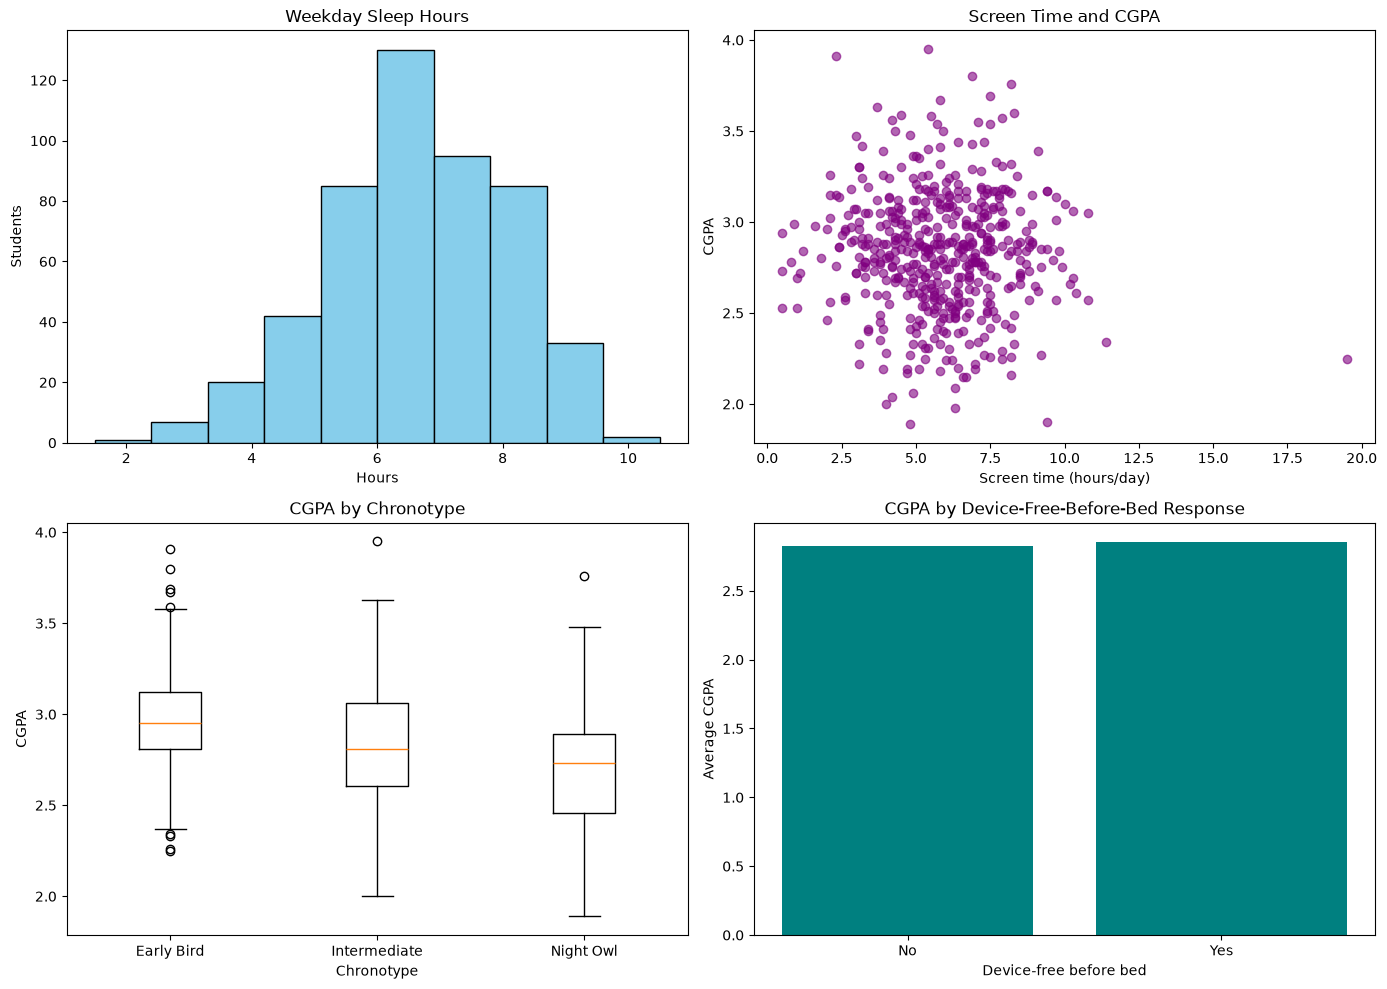

In [ ]:
fig, ax = plt.subplots(2, 2, figsize=(14, 10)) #creates a 2x2 grid of subplots with a figure size of 14 inches by 10 inches.

ax[0, 0].hist(
    df["avg_sleep_hours_weekday"].dropna(),
    bins=10, edgecolor="black", color="skyblue"
)
ax[0, 0].set(title="Weekday Sleep Hours", xlabel="Hours", ylabel="Students")

screen_cgpa = df[["daily_screen_time_hours", "cgpa"]].dropna()
ax[0, 1].scatter(
    screen_cgpa["daily_screen_time_hours"],
    screen_cgpa["cgpa"],
    alpha=0.6, color="purple"
)
ax[0, 1].set(title="Screen Time and CGPA", xlabel="Screen time (hours/day)", ylabel="CGPA")

groups = df["chronotype"].dropna().unique()
cgpa_groups = [
    df.loc[df["chronotype"] == group, "cgpa"].dropna()
    for group in groups
]
ax[1, 0].boxplot(cgpa_groups, tick_labels=groups)
ax[1, 0].set(title="CGPA by Chronotype", xlabel="Chronotype", ylabel="CGPA")

device_means = df.groupby("device_free_before_bed")["cgpa"].mean().dropna()
ax[1, 1].bar(device_means.index.astype(str), device_means.values, color="teal")
ax[1, 1].set(
    title="CGPA by Device-Free-Before-Bed Response",
    xlabel="Device-free before bed",
    ylabel="Average CGPA"
)

plt.tight_layout()
plt.show()